In [ ]:
!pip install -q transformers sentencepiece protobuf pandas

import os, re, json
import pandas as pd
import torch
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

required = ["train.csv", "val.csv", "test.csv", "labels.json"]
missing = [f for f in required if not os.path.exists(f)]
print("Working dir:", os.getcwd())
print("Missing files:", missing if missing else "none, ready to go")
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Switch Runtime > Change runtime type > T4 GPU first"
print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Working dir: /content/drive/MyDrive/hausa_news_project
Missing files: none, ready to go
CUDA available: True
GPU: Tesla T4


In [ ]:
import time, random, glob, gc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn as nn
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv"); test = pd.read_csv("test.csv")
meta = json.load(open("labels.json"))
id2label = {int(k): v for k, v in meta["id2label"].items()}
label_names = [id2label[i] for i in range(len(id2label))]
NUM_CLASSES = len(label_names)
X_train, y_train = train["text_clean"], train["label_id"].values
X_val,   y_val   = val["text_clean"],   val["label_id"].values
X_test,  y_test  = test["text_clean"],  test["label_id"].values


RESULTS_FILE = "results.json"
try: RESULTS = json.load(open(RESULTS_FILE))
except FileNotFoundError: RESULTS = []

def compute_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": p,
            "macro_recall": r, "macro_f1": f1, "weighted_f1": f1_score(y_true, y_pred, average="weighted")}

def log_result(name, val_metrics, test_metrics=None, notes=""):
    row = {"model": name, "notes": notes, **{f"val_{k}": round(v, 4) for k, v in val_metrics.items()}}
    if test_metrics: row.update({f"test_{k}": round(v, 4) for k, v in test_metrics.items()})
    RESULTS[:] = [r for r in RESULTS if r["model"] != name]
    RESULTS.append(row)
    json.dump(RESULTS, open(RESULTS_FILE, "w"), indent=2)

def full_report(name, y_true, y_pred, X_text, prefix="final"):
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion matrix: {name}\n(colour = row-normalised, numbers = counts)")
    plt.tight_layout(); plt.savefig(f"{prefix}_confusion_matrix.png", dpi=150); plt.show()
    err = pd.DataFrame({"text": X_text.values, "true": [id2label[i] for i in y_true],
                        "pred": [id2label[i] for i in y_pred]})
    err = err[err["true"] != err["pred"]]
    err.to_csv(f"{prefix}_errors.csv", index=False)
    print(f"Misclassified: {len(err)} / {len(y_true)} -> saved {prefix}_errors.csv")
    return err

Device: cuda


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader, Dataset

slug = lambda s: re.sub(r"\W+", "_", s.strip())

def encode_docs(tok, texts, max_len, strategy="head", tail_frac=0.25):
    """Return token-id lists that fit in max_len, special tokens included.
       head      : keep the first tokens
       head+tail : keep the first 75% and the last 25% of the token budget
       Single-sequence format for XLM-R / AfriBERTa: <s> tokens </s>"""
    start_id = tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id
    end_id   = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
    assert start_id is not None and end_id is not None, "Tokenizer has no start/end token ids"
    budget = max_len - 2
    all_ids = tok(texts, add_special_tokens=False, truncation=False)["input_ids"]
    out = []
    for ids in all_ids:
        if len(ids) > budget:
            if strategy == "head":
                ids = ids[:budget]
            else:
                tail = int(budget * tail_frac)
                ids = ids[:budget - tail] + ids[-tail:]
        out.append([start_id] + ids + [end_id])
    return out

In [ ]:
class DocDS(Dataset):
    def __init__(self, enc, labels): self.enc, self.labels = enc, labels
    def __len__(self): return len(self.enc)
    def __getitem__(self, i): return self.enc[i], int(self.labels[i])

def make_collate(pad_id):
    def collate(batch):
        seqs, ys = zip(*batch)
        L = max(len(s) for s in seqs)
        ids = torch.full((len(seqs), L), pad_id, dtype=torch.long)
        attn = torch.zeros((len(seqs), L), dtype=torch.long)
        for i, s in enumerate(seqs):
            ids[i, :len(s)] = torch.tensor(s); attn[i, :len(s)] = 1
        return ids, attn, torch.tensor(ys, dtype=torch.long)
    return collate

In [ ]:
os.makedirs("preds", exist_ok=True)
os.makedirs("best_transformer", exist_ok=True)
BEST_META = "best_transformer/meta.json"

@torch.no_grad()
def get_logits(model, loader, use_amp):
    model.eval(); outs = []
    for input_ids, attn, _ in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            lg = model(input_ids=input_ids.to(device), attention_mask=attn.to(device)).logits
        outs.append(lg.float().cpu())
    return torch.cat(outs).numpy()

def run_experiment(run_name, model_id, max_len=256, strategy="head", lr=2e-5, epochs=6,
                   batch_size=16, grad_accum=1, patience=3, warmup_frac=0.1, weight_decay=0.01, seed=42, save_best=True):
    out = f"preds/{slug(run_name)}.npz"
    if os.path.exists(out):
        d = np.load(out)
        print(f"{run_name:34s} cached, val macro-F1={float(d['val_f1']):.4f}")
        return float(d["val_f1"])

    t0 = time.time(); set_seed(seed); use_amp = device.type == "cuda"
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id, num_labels=NUM_CLASSES, id2label=id2label,
        label2id={v: k for k, v in id2label.items()}).to(device)
    eff_len = min(max_len, model.config.max_position_embeddings - 2)
    pad_id = tok.pad_token_id

    enc_tr = encode_docs(tok, X_train.tolist(), eff_len, strategy)
    enc_va = encode_docs(tok, X_val.tolist(),   eff_len, strategy)
    enc_te = encode_docs(tok, X_test.tolist(),  eff_len, strategy)
    collate = make_collate(pad_id)
    tr_loader = DataLoader(DocDS(enc_tr, y_train), batch_size=batch_size, shuffle=True, collate_fn=collate)
    va_loader = DataLoader(DocDS(enc_va, y_val), batch_size=32, shuffle=False, collate_fn=collate)
    te_loader = DataLoader(DocDS(enc_te, y_test), batch_size=32, shuffle=False, collate_fn=collate)

    no_decay = ["bias", "LayerNorm.weight"]
    params = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
               "weight_decay": weight_decay},
              {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
               "weight_decay": 0.0}]
    opt = torch.optim.AdamW(params, lr=lr)
    steps_per_epoch = -(-len(tr_loader) // grad_accum)
    total_steps = steps_per_epoch * epochs
    sched = get_linear_schedule_with_warmup(opt, int(warmup_frac * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss()

    best_f1, best_state, bad, hist = -1, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); running = 0; opt.zero_grad()
        for i, (input_ids, attn, yb) in enumerate(tr_loader):
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=input_ids.to(device), attention_mask=attn.to(device)).logits
            loss = loss_fn(logits.float(), yb.to(device)) / grad_accum
            scaler.scale(loss).backward()
            running += loss.item() * grad_accum * len(yb)
            if (i + 1) % grad_accum == 0 or (i + 1) == len(tr_loader):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad()
        vf1 = f1_score(y_val, get_logits(model, va_loader, use_amp).argmax(1), average="macro")
        hist.append((ep, running / len(X_train), float(vf1)))
        print(f"   epoch {ep}  train_loss={running/len(X_train):.4f}  val_macro_F1={vf1:.4f}")
        if vf1 > best_f1:
            best_f1, bad = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"   early stop at epoch {ep}"); break

    model.load_state_dict(best_state)
    val_logits  = get_logits(model, va_loader, use_amp)
    test_logits = get_logits(model, te_loader, use_amp)
    cfg = dict(model_id=model_id, max_len=eff_len, strategy=strategy, lr=lr, epochs_run=len(hist),
               batch_size=batch_size, grad_accum=grad_accum, seed=seed)
    np.savez(out, name=run_name, val_logits=val_logits, test_logits=test_logits,
             val_f1=best_f1, hist=json.dumps(hist), config=json.dumps(cfg))


    best_overall = json.load(open(BEST_META))["val_f1"] if os.path.exists(BEST_META) else -1
    if save_best and best_f1 > best_overall:
        model.save_pretrained("best_transformer"); tok.save_pretrained("best_transformer")
        json.dump({"val_f1": best_f1, "run": run_name, **cfg}, open(BEST_META, "w"))
        print("   saved as new best model -> best_transformer/")

    vm = compute_metrics(y_val, val_logits.argmax(1))
    log_result(run_name, vm, notes=f"{model_id}, len={eff_len}, trunc={strategy}, lr={lr}, "
                                   f"bs={batch_size}x{grad_accum}, epochs={len(hist)}")
    print(f"{run_name:34s} val acc={vm['accuracy']:.3f}  macro-F1={vm['macro_f1']:.3f}  ({time.time()-t0:.0f}s)")
    del model, opt, best_state; gc.collect(); torch.cuda.empty_cache()
    return best_f1

In [ ]:
PHASE1 = [
    # (run name,                    model id,                     learning rate)
    ("AfroXLMR-base | head256",   "Davlan/afro-xlmr-base",     2e-5),
    ("AfriBERTa-base | head256",  "castorini/afriberta_base",  5e-5),
    ("XLM-R-base | head256",      "xlm-roberta-base",          2e-5),
]
phase1 = {}
for name, mid, lr in PHASE1:
    print(f"\n### {name}")
    phase1[name] = (run_experiment(name, mid, max_len=256, strategy="head", lr=lr), mid, lr)
print("\nPhase 1 val macro-F1:", {k: round(v[0], 4) for k, v in phase1.items()})


### AfroXLMR-base | head256


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexin

   epoch 1  train_loss=1.2932  val_macro_F1=0.9022
   epoch 2  train_loss=0.2865  val_macro_F1=0.8863
   epoch 3  train_loss=0.1438  val_macro_F1=0.8994
   epoch 4  train_loss=0.0810  val_macro_F1=0.9121
   epoch 5  train_loss=0.0413  val_macro_F1=0.8944
   epoch 6  train_loss=0.0203  val_macro_F1=0.8975


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence len

   epoch 1  train_loss=1.3907  val_macro_F1=0.8218
   epoch 2  train_loss=0.4989  val_macro_F1=0.8811
   epoch 3  train_loss=0.2852  val_macro_F1=0.8780
   epoch 4  train_loss=0.1816  val_macro_F1=0.8801
   epoch 5  train_loss=0.1375  val_macro_F1=0.8855
   epoch 6  train_loss=0.0992  val_macro_F1=0.8901
XLM-R-base | head256               val acc=0.899  macro-F1=0.890  (294s)

Phase 1 val macro-F1: {'AfroXLMR-base | head256': 0.9121, 'AfriBERTa-base | head256': 0.9049, 'XLM-R-base | head256': 0.8901}


In [ ]:
win_name = max(phase1, key=lambda k: phase1[k][0])
_, win_id, win_lr = phase1[win_name]
short = win_name.split(" | ")[0]
print("Phase 1 winner:", win_name)

run_experiment(f"{short} | head+tail256", win_id, max_len=256, strategy="head+tail", lr=win_lr)
run_experiment(f"{short} | head512", win_id, max_len=512, strategy="head", lr=win_lr,
               batch_size=8, grad_accum=2)

Phase 1 winner: AfroXLMR-base | head256


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexin

   epoch 1  train_loss=1.2836  val_macro_F1=0.9071
   epoch 2  train_loss=0.2859  val_macro_F1=0.8949
   epoch 3  train_loss=0.1482  val_macro_F1=0.8934
   epoch 4  train_loss=0.0855  val_macro_F1=0.8974
   early stop at epoch 4
AfroXLMR-base | head+tail256       val acc=0.915  macro-F1=0.907  (191s)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexin

   epoch 1  train_loss=1.2925  val_macro_F1=0.8977
   epoch 2  train_loss=0.2728  val_macro_F1=0.8938
   epoch 3  train_loss=0.1369  val_macro_F1=0.9018
   epoch 4  train_loss=0.0927  val_macro_F1=0.8972
   epoch 5  train_loss=0.0546  val_macro_F1=0.9004
   epoch 6  train_loss=0.0307  val_macro_F1=0.9042
AfroXLMR-base | head512            val acc=0.912  macro-F1=0.904  (495s)


0.9042070588667475

Transformer runs ranked by validation macro-F1:
  0.9121  AfroXLMR-base | head256
  0.9071  AfroXLMR-base | head+tail256
  0.9049  AfriBERTa-base | head256
  0.9042  AfroXLMR-base | head512
  0.8901  XLM-R-base | head256

VAL : {'accuracy': 0.918, 'macro_precision': 0.911, 'macro_recall': 0.916, 'macro_f1': 0.912, 'weighted_f1': 0.918}
TEST: {'accuracy': 0.914, 'macro_precision': 0.908, 'macro_recall': 0.906, 'macro_f1': 0.907, 'weighted_f1': 0.913}

===== TRANSFORMER: AfroXLMR-base | head256 =====
               precision    recall  f1-score   support

     business      0.808     0.787     0.797        80
entertainment      0.939     0.920     0.929       100
       health      0.911     0.929     0.920        99
     politics      0.901     0.910     0.905       100
     religion      0.932     0.970     0.950        99
       sports      0.990     0.980     0.985       100
   technology      0.877     0.847     0.862        59

     accuracy                          0.914       637

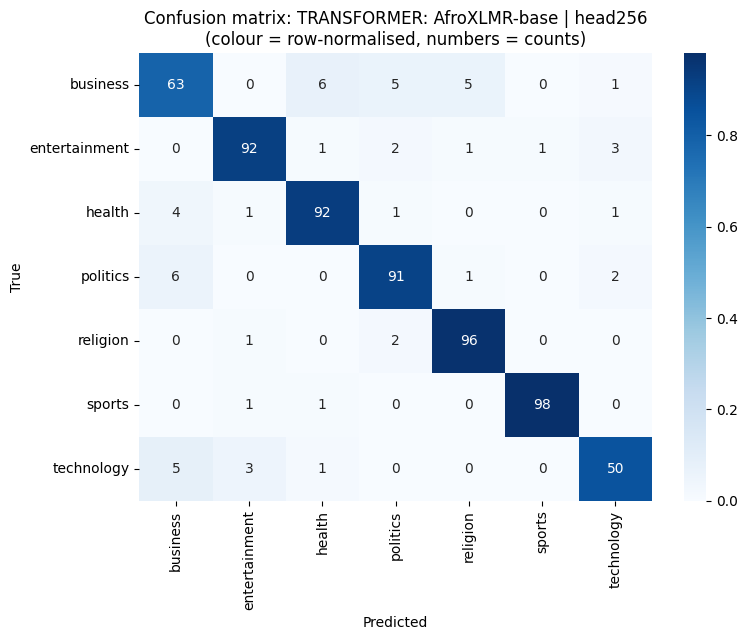

Misclassified: 55 / 637 -> saved transformer_errors.csv
                                         model  val_accuracy  val_macro_f1  test_accuracy  test_macro_f1
                       AfroXLMR-base | head256        0.9180        0.9121            NaN            NaN
          TRANSFORMER: AfroXLMR-base | head256        0.9180        0.9121         0.9137         0.9071
               BASELINE: TFIDF LogReg (C=10.0)        0.9180        0.9115         0.8870         0.8753
        PREPROC: LogReg norm=False tok=default        0.9180        0.9115            NaN            NaN
                           TFIDF-word + LogReg        0.9180        0.9115            NaN            NaN
         PREPROC: LogReg norm=True tok=default        0.9148        0.9081            NaN            NaN
                  AfroXLMR-base | head+tail256        0.9148        0.9071            NaN            NaN
PREPROC: LogReg norm=False tok=keep-apostrophe        0.9117        0.9056            NaN            NaN

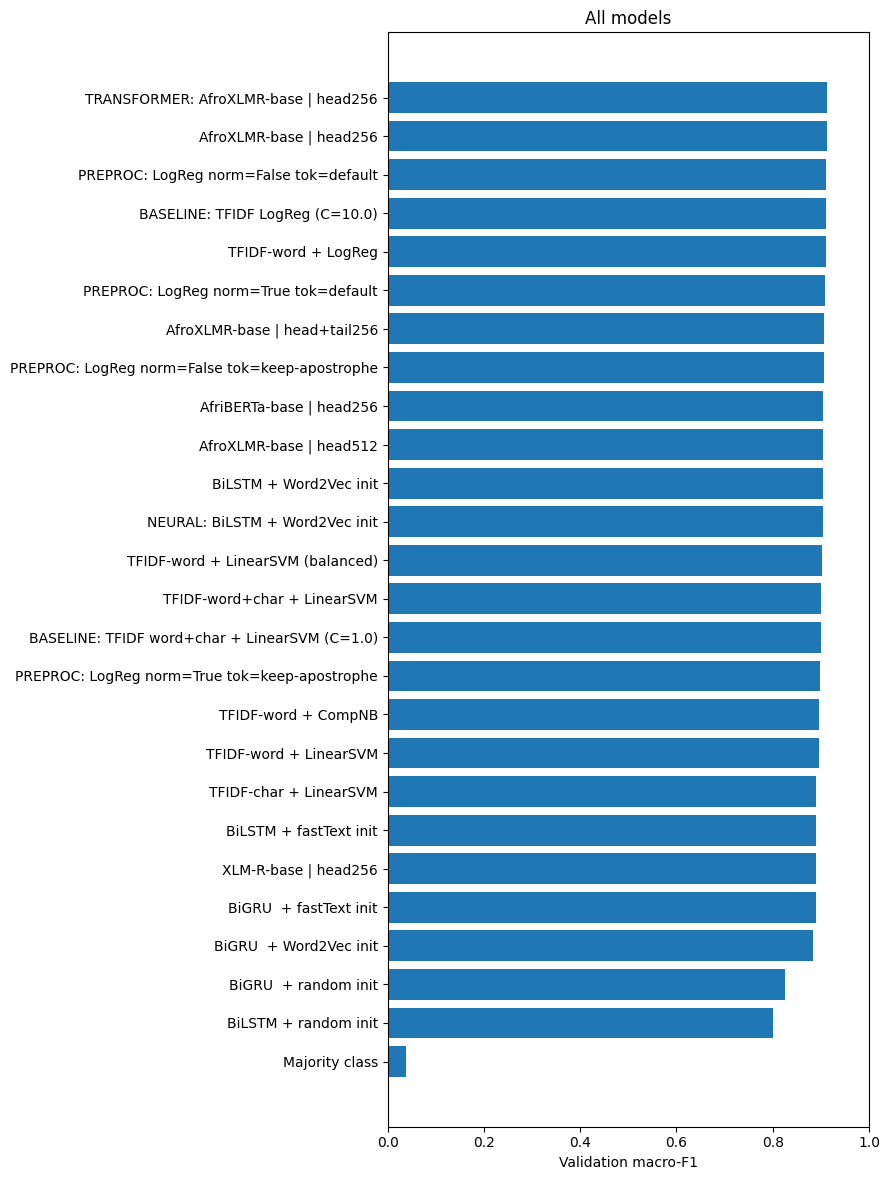

In [ ]:
runs = []
for f in glob.glob("preds/*.npz"):
    d = np.load(f)
    if str(d["name"]).startswith("SEED"): continue
    runs.append((str(d["name"]), float(d["val_f1"]), f))
runs.sort(key=lambda r: -r[1])
print("Transformer runs ranked by validation macro-F1:")
for n, v, _ in runs: print(f"  {v:.4f}  {n}")

best_name, best_val, best_file = runs[0]
d = np.load(best_file)
val_pred, test_pred = d["val_logits"].argmax(1), d["test_logits"].argmax(1)
val_m, test_m = compute_metrics(y_val, val_pred), compute_metrics(y_test, test_pred)

final_name = f"TRANSFORMER: {best_name}"
log_result(final_name, val_m, test_m, notes="best transformer by val macro-F1, test evaluated once")
print("\nVAL :", {k: round(v, 3) for k, v in val_m.items()})
print("TEST:", {k: round(v, 3) for k, v in test_m.items()})
errors_transformer = full_report(final_name, y_test, test_pred, X_test, prefix="transformer")


table = pd.DataFrame(RESULTS)
cols = [c for c in ["model", "val_accuracy", "val_macro_f1", "test_accuracy", "test_macro_f1"] if c in table]
print(table[cols].sort_values("val_macro_f1", ascending=False).to_string(index=False))

plot_df = table.sort_values("val_macro_f1")
plt.figure(figsize=(9, 0.4 * len(plot_df) + 1.5))
plt.barh(plot_df["model"], plot_df["val_macro_f1"])
plt.xlabel("Validation macro-F1"); plt.title("All models")
plt.xlim(max(0, plot_df["val_macro_f1"].min() - 0.05), 1)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

In [ ]:

for lr in [1e-5, 3e-5, 5e-5]:
    run_experiment(f"AfroXLMR-base | head256 | lr{lr}", "Davlan/afro-xlmr-base", 256, "head", lr)


for s in [1, 2, 3]:
    for nm, mid, lr in [("AfroXLMR-base", "Davlan/afro-xlmr-base", 2e-5),
                        ("AfriBERTa-base", "castorini/afriberta_base", 5e-5)]:
        run_experiment(f"SEED{s} {nm} | head256", mid, 256, "head", lr, seed=s, save_best=False)


rows = []
for f in glob.glob("preds/*.npz"):
    d = np.load(f); n = str(d["name"]); base = re.sub(r"^SEED\d+ ", "", n)
    if base.endswith("| head256") and ("AfroXLMR" in base or "AfriBERTa" in base):
        rows.append({"model": base.split(" | ")[0], "val_f1": float(d["val_f1"]),
                     "test_f1": f1_score(y_test, d["test_logits"].argmax(1), average="macro")})
print(pd.DataFrame(rows).groupby("model").agg(["mean", "std", "count"]).round(4))

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexin

   epoch 1  train_loss=1.3407  val_macro_F1=0.8675
   epoch 2  train_loss=0.3139  val_macro_F1=0.8998
   epoch 3  train_loss=0.1686  val_macro_F1=0.8957
   epoch 4  train_loss=0.0864  val_macro_F1=0.8921
   epoch 5  train_loss=0.0435  val_macro_F1=0.9027
   epoch 6  train_loss=0.0282  val_macro_F1=0.9084
SEED3 AfroXLMR-base | head256      val acc=0.915  macro-F1=0.908  (305s)


Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_base
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   epoch 1  train_loss=0.8339  val_macro_F1=0.8813
   epoch 2  train_loss=0.2140  val_macro_F1=0.8996
   epoch 3  train_loss=0.0771  val_macro_F1=0.8931
   epoch 4  train_loss=0.0194  val_macro_F1=0.8945
   epoch 5  train_loss=0.0048  val_macro_F1=0.9015
   epoch 6  train_loss=0.0016  val_macro_F1=0.9049
SEED3 AfriBERTa-base | head256     val acc=0.912  macro-F1=0.905  (171s)
                val_f1               test_f1              
                  mean     std count    mean     std count
model                                                     
AfriBERTa-base  0.9063  0.0022     4  0.8925  0.0094     4
AfroXLMR-base   0.9080  0.0030     4  0.9036  0.0037     4


['model', 'notes', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_weighted_f1', 'test_accuracy', 'test_macro_precision', 'test_macro_recall', 'test_macro_f1', 'test_weighted_f1']


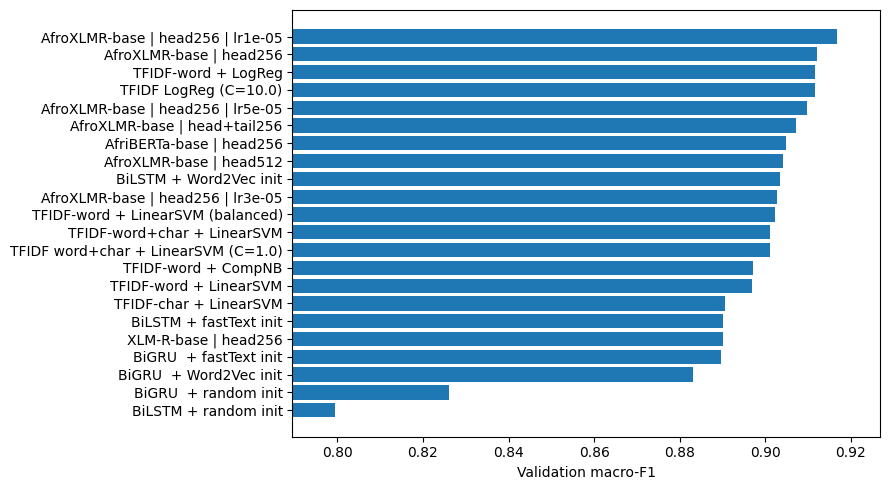

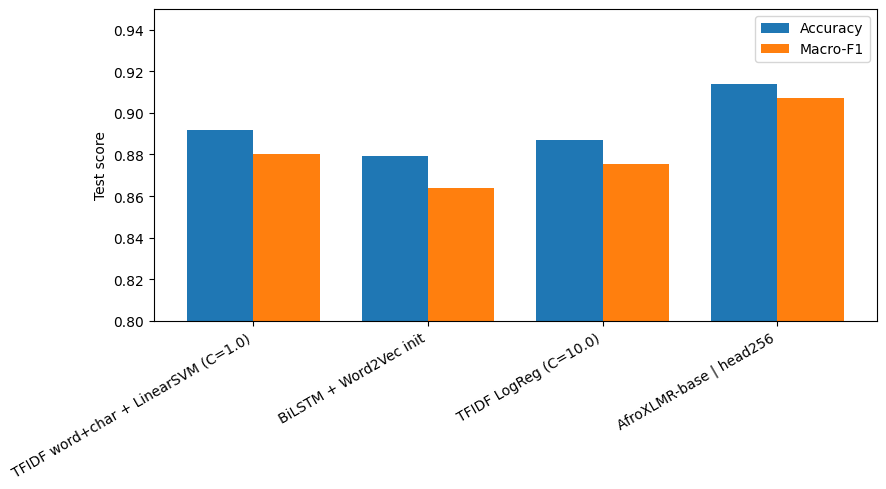

In [ ]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame(json.load(open("results.json")))
print(df.columns.tolist())
vf1  = next(c for c in df.columns if "val" in c.lower() and "f1" in c.lower())
tacc = next(c for c in df.columns if "test" in c.lower() and "acc" in c.lower())
tf1  = next(c for c in df.columns if "test" in c.lower() and "f1" in c.lower())

df = df[~df["model"].str.startswith(("PREPROC", "SEED", "Majority"))].copy()
df["name"] = df["model"].str.replace(r"^(TRANSFORMER|NEURAL|BASELINE): ", "", regex=True)

v = df[df[vf1].notna()].drop_duplicates("name").sort_values(vf1)
plt.figure(figsize=(9, 5)); plt.barh(v["name"], v[vf1])
plt.xlim(v[vf1].min() - 0.01, v[vf1].max() + 0.01); plt.xlabel("Validation macro-F1")
plt.tight_layout(); plt.savefig("validation_comparison.png", dpi=200); plt.show()

t = df[df[tf1].notna()].drop_duplicates("name")
x, w = np.arange(len(t)), 0.38
plt.figure(figsize=(9, 5))
plt.bar(x - w/2, t[tacc], w, label="Accuracy"); plt.bar(x + w/2, t[tf1], w, label="Macro-F1")
plt.xticks(x, t["name"], rotation=30, ha="right"); plt.ylim(0.8, 0.95); plt.ylabel("Test score"); plt.legend()
plt.tight_layout(); plt.savefig("test_comparison.png", dpi=200); plt.show()